# Forest Proximity Tutorial (RF, ExtraTrees, RotationForest, IsolationForest)

This notebook demonstrates how to generate forest-based proximities using `forestgap`, embed them with PHATE, and compare embeddings across model families.

Workflow:
1. Set `TASK_TYPE` and `DATASET_SOURCE` at the top of the notebook.
2. Load dataset and split train/test.
3. Build proximities for each forest model.
4. Compute PHATE embedding from each model's proximity matrix.
5. Compare all embeddings in one final subplot figure.

In [1]:
from pathlib import Path
import sys

# Add parent directory to path to import local forestgap package
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
import warnings

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.ensemble import (
    RandomForestClassifier,
    RandomForestRegressor,
    ExtraTreesClassifier,
    ExtraTreesRegressor,
    IsolationForest,
)

from forestgap import (
    SIMULATION_DATASET_GENERATORS,
    load_openml_dataset,
    load_simulated_dataset,
    with_sparse_proximity,
)

warnings.filterwarnings(
    "ignore",
    message=r".*BaseEstimator\._validate_data.*",
    category=FutureWarning,
)

try:
    from aeon.classification.sklearn import RotationForestClassifier
    from aeon.regression.sklearn import RotationForestRegressor
    HAS_AEON = True
except Exception:
    HAS_AEON = False

try:
    from treeple import (
        ObliqueRandomForestClassifier,
        ObliqueRandomForestRegressor,
        PatchObliqueRandomForestClassifier,
        PatchObliqueRandomForestRegressor,
        ExtraObliqueRandomForestClassifier,
        ExtraObliqueRandomForestRegressor,
        HonestForestClassifier,
        UnsupervisedRandomForest,
        UnsupervisedObliqueRandomForest,
        ExtendedIsolationForest,
    )
    HAS_TREEPLE = True
except Exception:
    HAS_TREEPLE = False

try:
    import phate
except Exception as exc:
    raise ImportError(
        "PHATE is required for this tutorial. Install with: pip install phate"
    ) from exc

## 1) Global Configuration
Use `TASK_TYPE` to toggle supervised models between classification and regression, and `DATASET_SOURCE` to switch between OpenML and built-in synthetic data.
Synthetic datasets in `forestgap.datasets` are currently classification-only, so regression runs should keep `DATASET_SOURCE="openml"`.


In [2]:
# Toggle this value: 'classification' or 'regression'
TASK_TYPE = "classification"

# Toggle this value: 'openml' or 'synthetic'
DATASET_SOURCE = "synthetic"

RANDOM_STATE = 42
TEST_SIZE = 0.25
N_ESTIMATORS = 100
N_JOBS = -1
PROX_METHOD = "rfgap"

# IsolationForest-specific toggle: proximities can be built with or without bootstrap sampling
ISO_BOOTSTRAP = True

OPENML_DATASET_BY_TASK = {
    "classification": {
        "dataset_id": 40,
        "target_name": "Class",
    },
    "regression": {
        "dataset_id": 197,
        "target_name": "usr",
    },
}

SYNTHETIC_DATASET_CONFIG = {
    "name": "rotated_xor",
    "n_samples": 1000,
    "n_features": 2
    ,
}

if TASK_TYPE not in OPENML_DATASET_BY_TASK:
    raise ValueError("TASK_TYPE must be either 'classification' or 'regression'.")

if DATASET_SOURCE not in {"openml", "synthetic"}:
    raise ValueError("DATASET_SOURCE must be either 'openml' or 'synthetic'.")

if DATASET_SOURCE == "synthetic" and TASK_TYPE != "classification":
    raise ValueError(
        "Synthetic datasets in forestgap.datasets are currently classification-only."
    )

print(
    f"TASK_TYPE={TASK_TYPE}, DATASET_SOURCE={DATASET_SOURCE}, PROX_METHOD={PROX_METHOD}, "
    f"N_ESTIMATORS={N_ESTIMATORS}, N_JOBS={N_JOBS}, ISO_BOOTSTRAP={ISO_BOOTSTRAP}"
)
if DATASET_SOURCE == "openml":
    print(f"OpenML default: dataset_id={OPENML_DATASET_BY_TASK[TASK_TYPE]['dataset_id']}")
else:
    print(f"Synthetic default: {SYNTHETIC_DATASET_CONFIG['name']}")
    print(f"Available synthetic datasets: {sorted(SIMULATION_DATASET_GENERATORS)}")


TASK_TYPE=classification, DATASET_SOURCE=synthetic, PROX_METHOD=rfgap, N_ESTIMATORS=100, N_JOBS=-1, ISO_BOOTSTRAP=True
Synthetic default: rotated_xor
Available synthetic datasets: ['additive_interaction_correlated', 'diagonal_band', 'dual_projection_xor', 'oblique_gaussian_clusters', 'oblique_slab', 'rotated_linear_boundary', 'rotated_subspace_signal', 'rotated_xor', 'sparse_oblique_hyperplane']


## 2) Dataset Loading
Datasets can be loaded either from OpenML with `forestgap.datasets.load_openml_dataset` or from the built-in synthetic registry in `forestgap.datasets.py` with `forestgap.datasets.load_simulated_dataset`.
The synthetic registry currently provides classification datasets, while the OpenML path supports both classification and regression examples.


In [3]:
def build_feature_preprocessor(X: pd.DataFrame) -> ColumnTransformer:
    categorical_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
    numeric_cols = [col for col in X.columns if col not in categorical_cols]

    transformers = []
    if numeric_cols:
        numeric_pipeline = Pipeline(
            steps=[
                ("imputer", SimpleImputer(strategy="median")),
            ]
        )
        transformers.append(("num", numeric_pipeline, numeric_cols))

    if categorical_cols:
        categorical_pipeline = Pipeline(
            steps=[
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
            ]
        )
        transformers.append(("cat", categorical_pipeline, categorical_cols))

    if not transformers:
        raise ValueError("No usable feature columns were found in the dataset.")

    return ColumnTransformer(transformers=transformers, remainder="drop")


def normalize_loaded_dataset(X: pd.DataFrame, y_raw, task_type: str, dataset_label: str):
    X = X.copy() if isinstance(X, pd.DataFrame) else pd.DataFrame(X)

    if isinstance(y_raw, pd.DataFrame):
        if task_type == "classification":
            row_sums = y_raw.sum(axis=1).to_numpy()
            is_one_hot = y_raw.shape[1] > 1 and np.allclose(row_sums, 1.0)
            if is_one_hot:
                y = y_raw.to_numpy().argmax(axis=1)
                target_names = list(y_raw.columns)
                dataset_label = f"{dataset_label} [one-hot target -> argmax]"
                return X.reset_index(drop=True), y, target_names, dataset_label

        if y_raw.shape[1] != 1:
            raise ValueError(
                "This notebook expects a single target column, or a one-hot encoded "
                "classification target that can be collapsed with argmax."
            )
        y_raw = y_raw.iloc[:, 0]

    y_series = pd.Series(y_raw).copy()
    valid_mask = y_series.notna()
    if not valid_mask.all():
        X = X.loc[valid_mask].reset_index(drop=True)
        y_series = y_series.loc[valid_mask].reset_index(drop=True)

    if task_type == "classification":
        le = LabelEncoder()
        y = le.fit_transform(y_series.astype(str))
        target_names = list(le.classes_)
        return X, y, target_names, dataset_label

    y = pd.to_numeric(y_series, errors="coerce").to_numpy()
    if np.isnan(y).any():
        raise ValueError("Regression target contains non-numeric values.")
    return X, y, None, dataset_label


def load_dataset(task_type: str, dataset_source: str):
    if dataset_source == "openml":
        config = OPENML_DATASET_BY_TASK[task_type].copy()
        openml_dataset = load_openml_dataset(as_frame=True, **config)
        dataset_label = f"{openml_dataset.name} (OpenML {openml_dataset.dataset_id})"
        dataset_info = {
            "source": "openml",
            "dataset_id": openml_dataset.dataset_id,
        }
        X, y, target_names, dataset_label = normalize_loaded_dataset(
            openml_dataset.X,
            openml_dataset.y,
            task_type,
            dataset_label,
        )
        return X, y, target_names, dataset_label, dataset_info

    if task_type != "classification":
        raise ValueError(
            "Synthetic datasets in forestgap.datasets are currently classification-only."
        )

    synthetic_config = SYNTHETIC_DATASET_CONFIG.copy()
    synthetic_name = synthetic_config.pop("name")
    synthetic_config.setdefault("random_state", RANDOM_STATE)
    synthetic_dataset = load_simulated_dataset(synthetic_name, **synthetic_config)
    X = pd.DataFrame(synthetic_dataset.X, columns=synthetic_dataset.feature_names)
    dataset_label = f"{synthetic_dataset.name} (synthetic)"
    dataset_info = {
        "source": "synthetic",
        "metadata": synthetic_dataset.metadata,
    }
    X, y, target_names, dataset_label = normalize_loaded_dataset(
        X,
        synthetic_dataset.y,
        task_type,
        dataset_label,
    )
    return X, y, target_names, dataset_label, dataset_info


X, y, target_names, dataset_name, dataset_info = load_dataset(TASK_TYPE, DATASET_SOURCE)

stratify = y if TASK_TYPE == "classification" else None
try:
    X_train_raw, X_test_raw, y_train, y_test = train_test_split(
        X, y,
        test_size=TEST_SIZE,
        random_state=RANDOM_STATE,
        stratify=stratify,
    )
except ValueError as exc:
    if TASK_TYPE == "classification" and "least populated class" in str(exc):
        print("Warning: falling back to non-stratified split due to sparse class counts.")
        X_train_raw, X_test_raw, y_train, y_test = train_test_split(
            X, y,
            test_size=TEST_SIZE,
            random_state=RANDOM_STATE,
            stratify=None,
        )
    else:
        raise

feature_preprocessor = build_feature_preprocessor(X_train_raw)
X_train = feature_preprocessor.fit_transform(X_train_raw)
X_test = feature_preprocessor.transform(X_test_raw)

if sparse.issparse(X_train):
    X_train = X_train.toarray()
if sparse.issparse(X_test):
    X_test = X_test.toarray()

categorical_cols = X_train_raw.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
numeric_cols = [col for col in X_train_raw.columns if col not in categorical_cols]

print(f"Dataset source: {dataset_info['source']}")
print(f"Dataset: {dataset_name}")
if dataset_info["source"] == "openml":
    print(f"OpenML dataset id: {dataset_info['dataset_id']}")
else:
    print(f"Synthetic metadata: {dataset_info['metadata']}")
print(f"Raw train shape: {X_train_raw.shape}, Raw test shape: {X_test_raw.shape}")
print(f"Processed train shape: {X_train.shape}, Processed test shape: {X_test.shape}")
print(f"Numeric columns: {len(numeric_cols)}, Categorical columns: {len(categorical_cols)}")


Dataset source: synthetic
Dataset: rotated_xor (synthetic)
Synthetic metadata: {'angle_degrees': 35.0, 'feature_noise_std': 0.1, 'n_samples': 1000, 'n_features': 2}
Raw train shape: (750, 2), Raw test shape: (250, 2)
Processed train shape: (750, 2), Processed test shape: (250, 2)
Numeric columns: 2, Categorical columns: 0


## 3) Shared Helpers
These utilities standardize fitting, proximity extraction, and PHATE embedding across models.

In [4]:
def to_dense(mat):
    return mat.toarray() if sparse.issparse(mat) else np.asarray(mat)


def phate_from_proximity(P, random_state=42):
    P_dense = to_dense(P)
    op = phate.PHATE(random_state=random_state, n_jobs=N_JOBS)
    emb = op.fit_transform(P_dense)
    return emb


def plot_embedding(ax, emb, labels, title, task_type):
    if task_type == "classification":
        ax.scatter(emb[:, 0], emb[:, 1], c=labels, s=16, alpha=0.9, cmap="tab10")
    else:
        sc = ax.scatter(emb[:, 0], emb[:, 1], c=labels, s=16, alpha=0.9, cmap="viridis")
        plt.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)

    ax.set_title(title)
    ax.set_xlabel("PHATE-1")
    ax.set_ylabel("PHATE-2")


# Models that are unsupervised (fit without y, may need special bootstrap handling)
UNSUPERVISED_MODELS = {
    "IsolationForest", "ExtendedIsolationForest",
    "UnsupervisedRandomForest", "UnsupervisedObliqueRandomForest",
}


def build_model_key_to_class(task_type):
    if task_type == "classification":
        mapping = {
            "RandomForest": RandomForestClassifier,
            "ExtraTrees": ExtraTreesClassifier,
        }
        if HAS_AEON:
            mapping["RotationForest"] = RotationForestClassifier
        if HAS_TREEPLE:
            mapping["ObliqueRandomForest"] = ObliqueRandomForestClassifier
            mapping["PatchObliqueRandomForest"] = PatchObliqueRandomForestClassifier
            mapping["ExtraObliqueRandomForest"] = ExtraObliqueRandomForestClassifier
            mapping["HonestForest"] = HonestForestClassifier
    else:
        mapping = {
            "RandomForest": RandomForestRegressor,
            "ExtraTrees": ExtraTreesRegressor,
        }
        if HAS_AEON:
            mapping["RotationForest"] = RotationForestRegressor
        if HAS_TREEPLE:
            mapping["ObliqueRandomForest"] = ObliqueRandomForestRegressor
            mapping["PatchObliqueRandomForest"] = PatchObliqueRandomForestRegressor
            mapping["ExtraObliqueRandomForest"] = ExtraObliqueRandomForestRegressor

    mapping["IsolationForest"] = IsolationForest
    if HAS_TREEPLE:
        mapping["UnsupervisedRandomForest"] = UnsupervisedRandomForest
        mapping["UnsupervisedObliqueRandomForest"] = UnsupervisedObliqueRandomForest
        mapping["ExtendedIsolationForest"] = ExtendedIsolationForest
    return mapping


def fit_and_get_proximity(model_name, model_cls, X_train, y_train, task_type):
    ProxCls = with_sparse_proximity(model_cls)
    is_unsupervised = model_name in UNSUPERVISED_MODELS

    if is_unsupervised:
        kwargs = {
            "n_estimators": N_ESTIMATORS,
            "random_state": RANDOM_STATE,
            "prox_method": PROX_METHOD,
            "matrix_type": "sparse",
            "n_jobs": N_JOBS,
        }
        # IsolationForest / ExtendedIsolationForest: use ISO_BOOTSTRAP toggle
        if "IsolationForest" in model_name:
            kwargs["bootstrap"] = bool(ISO_BOOTSTRAP)
        else:
            # UnsupervisedRandomForest / UnsupervisedObliqueRandomForest: enable bootstrap for oob/rfgap
            kwargs["bootstrap"] = PROX_METHOD in ("oob", "rfgap")

        model = ProxCls(**kwargs)
        model.fit(X_train)
    else:
        kwargs = {
            "n_estimators": N_ESTIMATORS,
            "random_state": RANDOM_STATE,
            "prox_method": PROX_METHOD,
            "matrix_type": "sparse",
            "n_jobs": N_JOBS,
        }
        import inspect
        base_sig = inspect.signature(model_cls.__init__)
        if "bootstrap" in base_sig.parameters:
            kwargs["bootstrap"] = True
        if "oob_score" in base_sig.parameters:
            kwargs["oob_score"] = (PROX_METHOD == "rfgap")

        model = ProxCls(**kwargs)
        model.fit(X_train, y_train)

    P_train = model.get_proximities()
    return model, P_train

## 4) RandomForest Proximities + PHATE

Calculating PHATE...
  Running PHATE on 750 observations and 750 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 0.11 seconds.
    Calculating KNN search...
    Calculated KNN search in 1.92 seconds.
    Calculating affinities...
    Calculated affinities in 4.70 seconds.
  Calculated graph and diffusion operator in 6.74 seconds.
  Calculating optimal t...
    Automatically selected t = 12
  Calculated optimal t in 0.63 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 0.10 seconds.
  Calculating metric MDS...
  Calculated metric MDS in 8.19 seconds.
Calculated PHATE in 15.67 seconds.


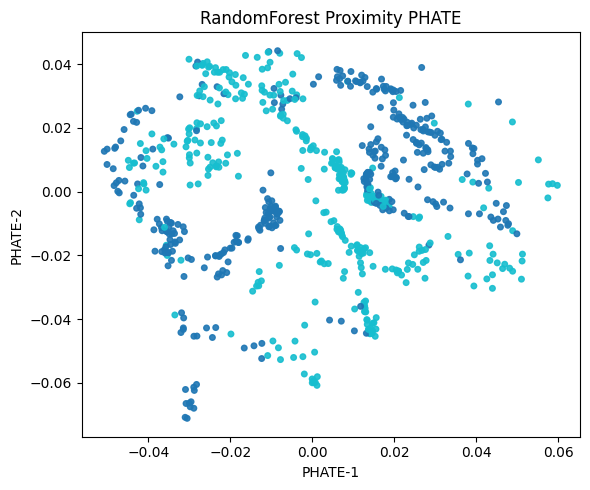

In [5]:
MODEL_MAP = build_model_key_to_class(TASK_TYPE)
results = {}

rf_model, rf_prox = fit_and_get_proximity("RandomForest", MODEL_MAP["RandomForest"], X_train, y_train, TASK_TYPE)
rf_emb = phate_from_proximity(rf_prox, random_state=RANDOM_STATE)
results["RandomForest"] = {"model": rf_model, "proximity": rf_prox, "embedding": rf_emb}

fig, ax = plt.subplots(figsize=(6, 5))
plot_embedding(ax, rf_emb, y_train, "RandomForest Proximity PHATE", TASK_TYPE)
plt.tight_layout()
plt.show()


## 5) ExtraTrees Proximities + PHATE

Calculating PHATE...
  Running PHATE on 750 observations and 750 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 0.25 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.08 seconds.
    Calculating affinities...
    Calculated affinities in 0.08 seconds.
  Calculated graph and diffusion operator in 0.42 seconds.
  Calculating optimal t...
    Automatically selected t = 20
  Calculated optimal t in 0.55 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 0.13 seconds.
  Calculating metric MDS...
    SGD-MDS may not have converged: stress changed by -1.6% in final iterations. Consider increasing n_iter or adjusting learning_rate.
  Calculated metric MDS in 8.42 seconds.
Calculated PHATE in 9.54 seconds.


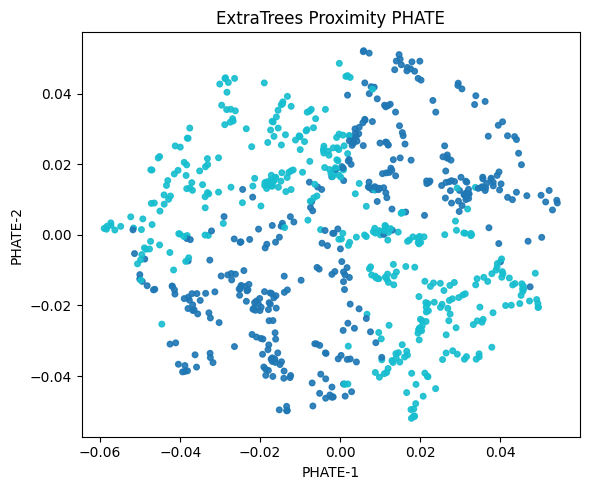

In [6]:
et_model, et_prox = fit_and_get_proximity("ExtraTrees", MODEL_MAP["ExtraTrees"], X_train, y_train, TASK_TYPE)
et_emb = phate_from_proximity(et_prox, random_state=RANDOM_STATE)
results["ExtraTrees"] = {"model": et_model, "proximity": et_prox, "embedding": et_emb}

fig, ax = plt.subplots(figsize=(6, 5))
plot_embedding(ax, et_emb, y_train, "ExtraTrees Proximity PHATE", TASK_TYPE)
plt.tight_layout()
plt.show()


## 6) RotationForest Proximities + PHATE
This section runs only when `aeon` is installed.

Calculating PHATE...
  Running PHATE on 750 observations and 750 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 0.22 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.04 seconds.
    Calculating affinities...
    Calculated affinities in 0.06 seconds.
  Calculated graph and diffusion operator in 0.33 seconds.
  Calculating optimal t...
    Automatically selected t = 18
  Calculated optimal t in 0.41 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 0.10 seconds.
  Calculating metric MDS...
    SGD-MDS may not have converged: stress changed by 2.0% in final iterations. Consider increasing n_iter or adjusting learning_rate.
  Calculated metric MDS in 8.55 seconds.
Calculated PHATE in 9.41 seconds.


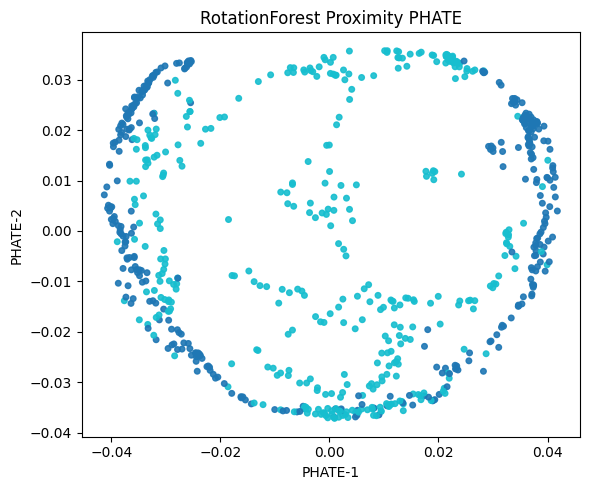

In [7]:
if "RotationForest" in MODEL_MAP:
    rot_model, rot_prox = fit_and_get_proximity("RotationForest", MODEL_MAP["RotationForest"], X_train, y_train, TASK_TYPE)
    rot_emb = phate_from_proximity(rot_prox, random_state=RANDOM_STATE)
    results["RotationForest"] = {"model": rot_model, "proximity": rot_prox, "embedding": rot_emb}

    fig, ax = plt.subplots(figsize=(6, 5))
    plot_embedding(ax, rot_emb, y_train, "RotationForest Proximity PHATE", TASK_TYPE)
    plt.tight_layout()
    plt.show()
else:
    print("Skipping RotationForest section because aeon is not installed.")


## 7) IsolationForest Proximities + PHATE
IsolationForest is unsupervised; we still color points by target values for visual comparison.

Calculating PHATE...
  Running PHATE on 750 observations and 750 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 0.24 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.04 seconds.
    Calculating affinities...
    Calculated affinities in 0.07 seconds.
  Calculated graph and diffusion operator in 0.37 seconds.
  Calculating optimal t...
    Automatically selected t = 25
  Calculated optimal t in 0.49 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 0.11 seconds.
  Calculating metric MDS...
  Calculated metric MDS in 10.61 seconds.
Calculated PHATE in 11.59 seconds.


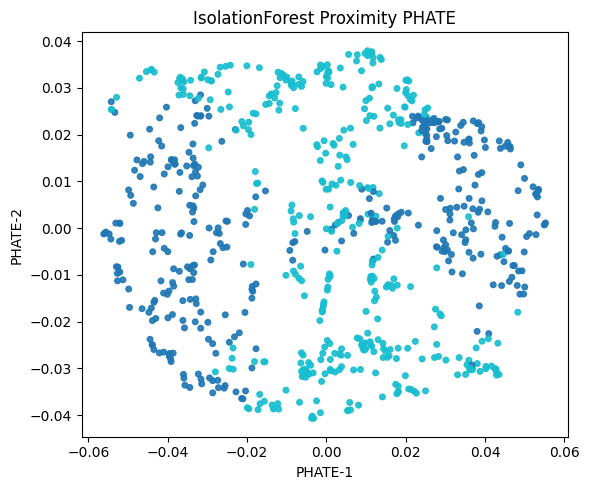

In [8]:
iso_model, iso_prox = fit_and_get_proximity("IsolationForest", MODEL_MAP["IsolationForest"], X_train, y_train, TASK_TYPE)
iso_emb = phate_from_proximity(iso_prox, random_state=RANDOM_STATE)
results["IsolationForest"] = {"model": iso_model, "proximity": iso_prox, "embedding": iso_emb}

fig, ax = plt.subplots(figsize=(6, 5))
plot_embedding(ax, iso_emb, y_train, "IsolationForest Proximity PHATE", TASK_TYPE)
plt.tight_layout()
plt.show()


## 8) ObliqueRandomForest Proximities + PHATE
Oblique splits consider linear combinations of features, enabling more flexible decision boundaries. Requires `treeple`.

Calculating PHATE...
  Running PHATE on 750 observations and 750 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 0.24 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.07 seconds.
    Calculating affinities...
    Calculated affinities in 0.08 seconds.
  Calculated graph and diffusion operator in 0.41 seconds.
  Calculating optimal t...
    Automatically selected t = 16
  Calculated optimal t in 0.60 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 0.08 seconds.
  Calculating metric MDS...
  Calculated metric MDS in 7.95 seconds.
Calculated PHATE in 9.05 seconds.


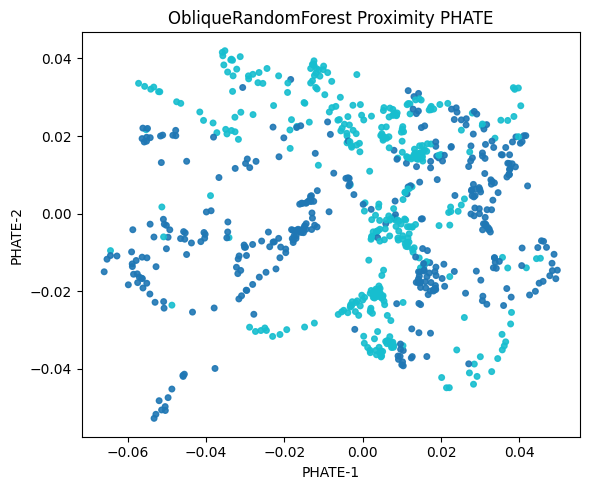

In [9]:
if "ObliqueRandomForest" in MODEL_MAP:
    obl_model, obl_prox = fit_and_get_proximity("ObliqueRandomForest", MODEL_MAP["ObliqueRandomForest"], X_train, y_train, TASK_TYPE)
    obl_emb = phate_from_proximity(obl_prox, random_state=RANDOM_STATE)
    results["ObliqueRandomForest"] = {"model": obl_model, "proximity": obl_prox, "embedding": obl_emb}

    fig, ax = plt.subplots(figsize=(6, 5))
    plot_embedding(ax, obl_emb, y_train, "ObliqueRandomForest Proximity PHATE", TASK_TYPE)
    plt.tight_layout()
    plt.show()
else:
    print("Skipping ObliqueRandomForest section because treeple is not installed.")

## 9) PatchObliqueRandomForest Proximities + PHATE
Patch-oblique trees split on linear combinations within local feature patches. Requires `treeple`.

Calculating PHATE...
  Running PHATE on 750 observations and 750 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 0.27 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.09 seconds.
    Calculating affinities...
    Calculated affinities in 0.12 seconds.
  Calculated graph and diffusion operator in 0.50 seconds.
  Calculating optimal t...
    Automatically selected t = 23
  Calculated optimal t in 0.64 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 0.15 seconds.
  Calculating metric MDS...
  Calculated metric MDS in 9.55 seconds.
Calculated PHATE in 10.86 seconds.


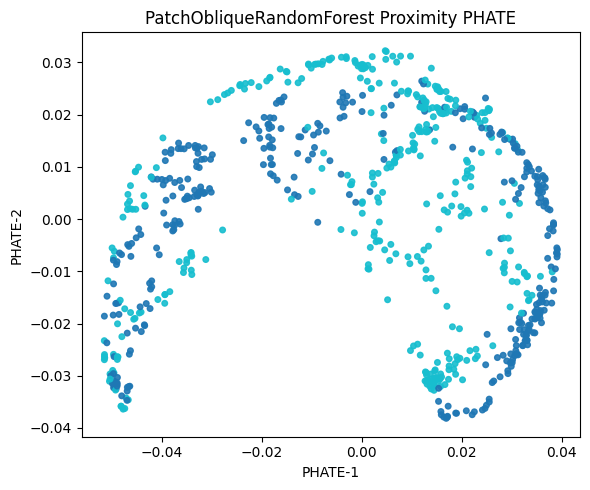

In [10]:
if "PatchObliqueRandomForest" in MODEL_MAP:
    pobl_model, pobl_prox = fit_and_get_proximity("PatchObliqueRandomForest", MODEL_MAP["PatchObliqueRandomForest"], X_train, y_train, TASK_TYPE)
    pobl_emb = phate_from_proximity(pobl_prox, random_state=RANDOM_STATE)
    results["PatchObliqueRandomForest"] = {"model": pobl_model, "proximity": pobl_prox, "embedding": pobl_emb}

    fig, ax = plt.subplots(figsize=(6, 5))
    plot_embedding(ax, pobl_emb, y_train, "PatchObliqueRandomForest Proximity PHATE", TASK_TYPE)
    plt.tight_layout()
    plt.show()
else:
    print("Skipping PatchObliqueRandomForest section because treeple is not installed.")

## 10) ExtraObliqueRandomForest Proximities + PHATE
Extra-oblique trees add further randomization to the oblique split selection. Requires `treeple`.

Calculating PHATE...
  Running PHATE on 750 observations and 750 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 0.28 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.07 seconds.
    Calculating affinities...
    Calculated affinities in 0.13 seconds.
  Calculated graph and diffusion operator in 0.50 seconds.
  Calculating optimal t...
    Automatically selected t = 27
  Calculated optimal t in 0.65 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 0.16 seconds.
  Calculating metric MDS...
    SGD-MDS may not have converged: stress changed by -2.2% in final iterations. Consider increasing n_iter or adjusting learning_rate.
  Calculated metric MDS in 11.14 seconds.
Calculated PHATE in 12.47 seconds.


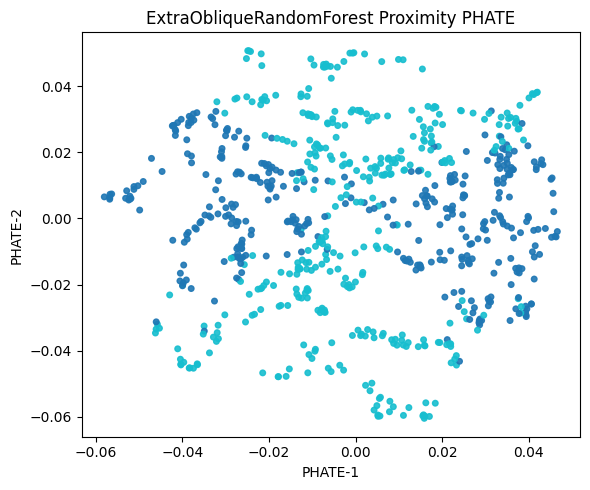

In [11]:
if "ExtraObliqueRandomForest" in MODEL_MAP:
    eobl_model, eobl_prox = fit_and_get_proximity("ExtraObliqueRandomForest", MODEL_MAP["ExtraObliqueRandomForest"], X_train, y_train, TASK_TYPE)
    eobl_emb = phate_from_proximity(eobl_prox, random_state=RANDOM_STATE)
    results["ExtraObliqueRandomForest"] = {"model": eobl_model, "proximity": eobl_prox, "embedding": eobl_emb}

    fig, ax = plt.subplots(figsize=(6, 5))
    plot_embedding(ax, eobl_emb, y_train, "ExtraObliqueRandomForest Proximity PHATE", TASK_TYPE)
    plt.tight_layout()
    plt.show()
else:
    print("Skipping ExtraObliqueRandomForest section because treeple is not installed.")

## 11) HonestForest Proximities + PHATE
Honest forests use separate subsets for structure (splits) and estimation (leaf predictions). Classification only. Requires `treeple`.

Calculating PHATE...
  Running PHATE on 750 observations and 750 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 0.18 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.05 seconds.
    Calculating affinities...
    Calculated affinities in 0.06 seconds.
  Calculated graph and diffusion operator in 0.30 seconds.
  Calculating optimal t...
    Automatically selected t = 17
  Calculated optimal t in 0.52 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 0.13 seconds.
  Calculating metric MDS...
    SGD-MDS may not have converged: stress changed by -1.3% in final iterations. Consider increasing n_iter or adjusting learning_rate.
  Calculated metric MDS in 7.94 seconds.
Calculated PHATE in 8.90 seconds.


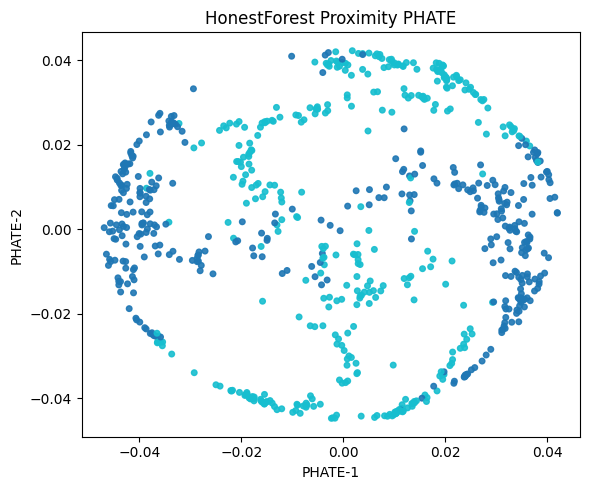

In [12]:
if "HonestForest" in MODEL_MAP:
    hf_model, hf_prox = fit_and_get_proximity("HonestForest", MODEL_MAP["HonestForest"], X_train, y_train, TASK_TYPE)
    hf_emb = phate_from_proximity(hf_prox, random_state=RANDOM_STATE)
    results["HonestForest"] = {"model": hf_model, "proximity": hf_prox, "embedding": hf_emb}

    fig, ax = plt.subplots(figsize=(6, 5))
    plot_embedding(ax, hf_emb, y_train, "HonestForest Proximity PHATE", TASK_TYPE)
    plt.tight_layout()
    plt.show()
else:
    print("Skipping HonestForest section (classification only, requires treeple).")

## 12) UnsupervisedRandomForest Proximities + PHATE
Unsupervised random forest learns structure without labels via synthetic target generation. Requires `treeple`.

Calculating PHATE...
  Running PHATE on 750 observations and 750 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 0.18 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.06 seconds.
    Calculating affinities...
    Calculated affinities in 0.13 seconds.
  Calculated graph and diffusion operator in 0.38 seconds.
  Calculating optimal t...
    Automatically selected t = 30
  Calculated optimal t in 0.46 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 0.09 seconds.
  Calculating metric MDS...
    SGD-MDS may not have converged: stress changed by -2.8% in final iterations. Consider increasing n_iter or adjusting learning_rate.
  Calculated metric MDS in 7.17 seconds.
Calculated PHATE in 8.12 seconds.


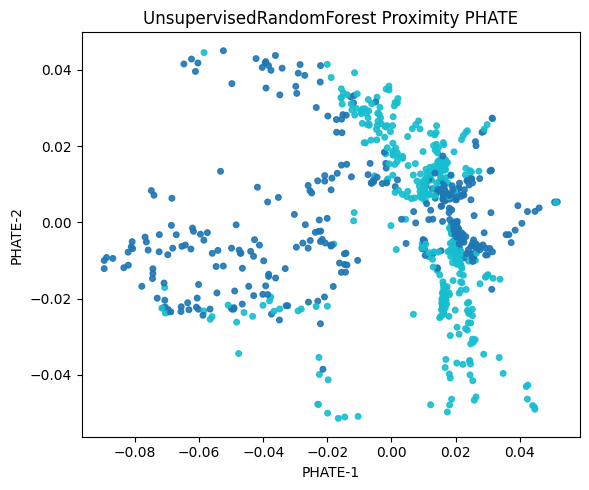

In [13]:
if "UnsupervisedRandomForest" in MODEL_MAP:
    urf_model, urf_prox = fit_and_get_proximity("UnsupervisedRandomForest", MODEL_MAP["UnsupervisedRandomForest"], X_train, y_train, TASK_TYPE)
    urf_emb = phate_from_proximity(urf_prox, random_state=RANDOM_STATE)
    results["UnsupervisedRandomForest"] = {"model": urf_model, "proximity": urf_prox, "embedding": urf_emb}

    fig, ax = plt.subplots(figsize=(6, 5))
    plot_embedding(ax, urf_emb, y_train, "UnsupervisedRandomForest Proximity PHATE", TASK_TYPE)
    plt.tight_layout()
    plt.show()
else:
    print("Skipping UnsupervisedRandomForest section because treeple is not installed.")

## 13) UnsupervisedObliqueRandomForest Proximities + PHATE
Unsupervised oblique random forest combines oblique (hyperplane) splits with unsupervised learning via synthetic target generation. Requires `treeple`.

Calculating PHATE...
  Running PHATE on 750 observations and 750 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 0.20 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.05 seconds.
    Calculating affinities...
    Calculated affinities in 0.11 seconds.
  Calculated graph and diffusion operator in 0.37 seconds.
  Calculating optimal t...
    Automatically selected t = 38
  Calculated optimal t in 0.47 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 0.10 seconds.
  Calculating metric MDS...
    SGD-MDS may not have converged: stress changed by -1.3% in final iterations. Consider increasing n_iter or adjusting learning_rate.
  Calculated metric MDS in 9.33 seconds.
Calculated PHATE in 10.29 seconds.


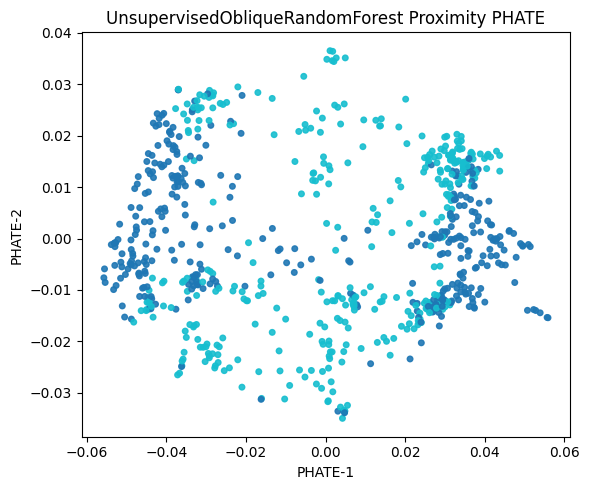

In [14]:
if "UnsupervisedObliqueRandomForest" in MODEL_MAP:
    uorf_model, uorf_prox = fit_and_get_proximity("UnsupervisedObliqueRandomForest", MODEL_MAP["UnsupervisedObliqueRandomForest"], X_train, y_train, TASK_TYPE)
    uorf_emb = phate_from_proximity(uorf_prox, random_state=RANDOM_STATE)
    results["UnsupervisedObliqueRandomForest"] = {"model": uorf_model, "proximity": uorf_prox, "embedding": uorf_emb}

    fig, ax = plt.subplots(figsize=(6, 5))
    plot_embedding(ax, uorf_emb, y_train, "UnsupervisedObliqueRandomForest Proximity PHATE", TASK_TYPE)
    plt.tight_layout()
    plt.show()
else:
    print("Skipping UnsupervisedObliqueRandomForest section because treeple is not installed.")

## 14) ExtendedIsolationForest Proximities + PHATE
Extended isolation forest uses hyperplane splits instead of axis-aligned ones, improving anomaly detection in multi-dimensional data. Requires `treeple`.

Calculating PHATE...
  Running PHATE on 750 observations and 750 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 0.20 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.05 seconds.
    Calculating affinities...
    Calculated affinities in 0.08 seconds.
  Calculated graph and diffusion operator in 0.35 seconds.
  Calculating optimal t...
    Automatically selected t = 19
  Calculated optimal t in 0.42 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 0.09 seconds.
  Calculating metric MDS...
  Calculated metric MDS in 7.60 seconds.
Calculated PHATE in 8.46 seconds.


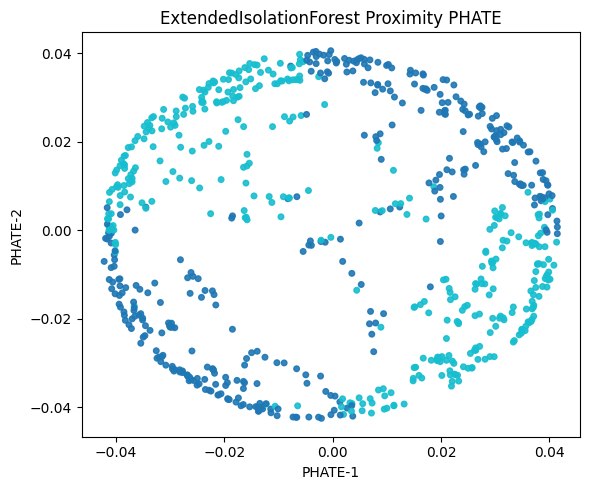

In [15]:
if "ExtendedIsolationForest" in MODEL_MAP:
    eif_model, eif_prox = fit_and_get_proximity("ExtendedIsolationForest", MODEL_MAP["ExtendedIsolationForest"], X_train, y_train, TASK_TYPE)
    eif_emb = phate_from_proximity(eif_prox, random_state=RANDOM_STATE)
    results["ExtendedIsolationForest"] = {"model": eif_model, "proximity": eif_prox, "embedding": eif_emb}

    fig, ax = plt.subplots(figsize=(6, 5))
    plot_embedding(ax, eif_emb, y_train, "ExtendedIsolationForest Proximity PHATE", TASK_TYPE)
    plt.tight_layout()
    plt.show()
else:
    print("Skipping ExtendedIsolationForest section because treeple is not installed.")

## 15) Final Comparison: All Forest Proximity PHATE Embeddings
This summary figure compares all available model embeddings in one place.

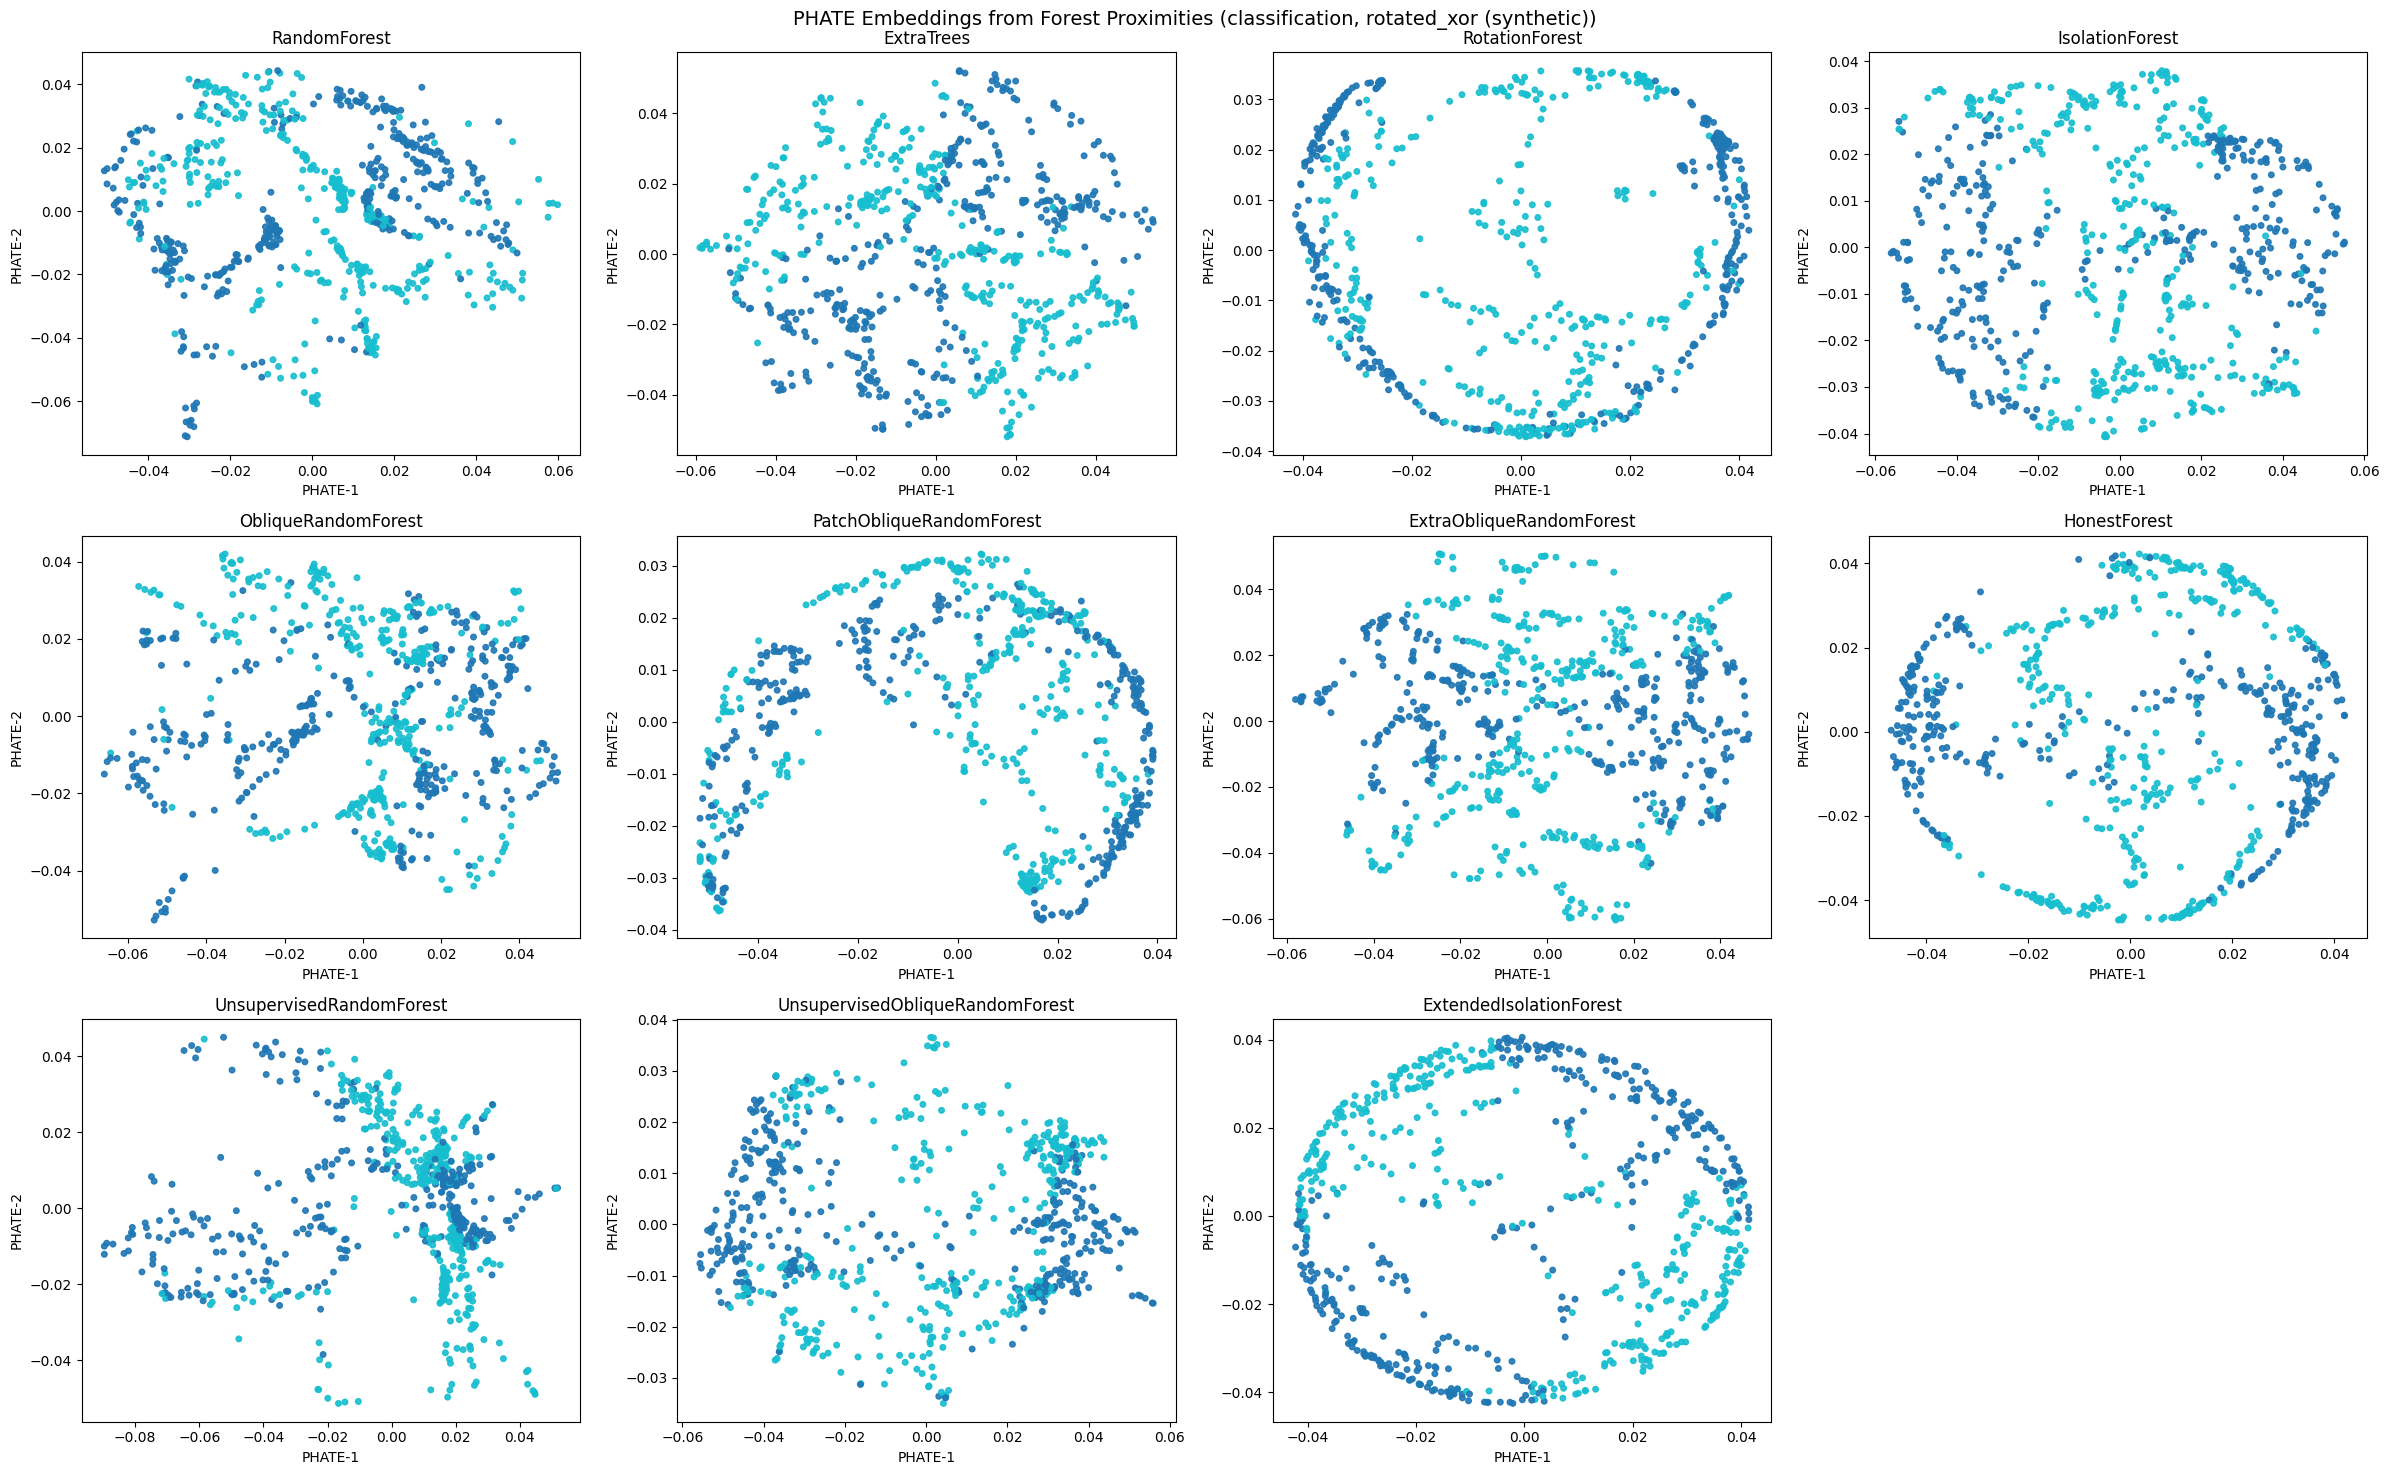

In [16]:
model_order = [
    "RandomForest", "ExtraTrees", "RotationForest", "IsolationForest",
    "ObliqueRandomForest", "PatchObliqueRandomForest", "ExtraObliqueRandomForest",
    "HonestForest", "UnsupervisedRandomForest", "UnsupervisedObliqueRandomForest",
    "ExtendedIsolationForest",
]
available = [m for m in model_order if m in results]
n_models = len(available)

ncols = min(n_models, 4)
nrows = (n_models + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 5 * nrows), sharex=False, sharey=False)
axes = np.atleast_1d(axes).ravel()

for i, model_name in enumerate(available):
    ax = axes[i]
    emb = results[model_name]["embedding"]
    plot_embedding(ax, emb, y_train, model_name, TASK_TYPE)

# Hide unused axes
for j in range(n_models, len(axes)):
    axes[j].axis("off")

fig.suptitle(f"PHATE Embeddings from Forest Proximities ({TASK_TYPE}, {dataset_name})", fontsize=14)
plt.tight_layout()
plt.show()

In [17]:
def compute_oob_accuracy(model, y_true):
    y_true = np.asarray(y_true)

    if hasattr(model, "oob_decision_function_"):
        oob = np.asarray(model.oob_decision_function_)
        if oob.ndim == 1:
            valid_mask = np.isfinite(oob)
            y_pred = (oob[valid_mask] >= 0.5).astype(int)
        else:
            valid_mask = np.isfinite(oob).all(axis=1) & (np.abs(oob).sum(axis=1) > 0)
            y_pred = np.argmax(oob[valid_mask], axis=1)

        if valid_mask.any():
            return float(np.mean(y_pred == y_true[valid_mask]))

    if hasattr(model, "oob_prediction_"):
        oob_pred = np.asarray(model.oob_prediction_)
        if oob_pred.ndim == 1:
            valid_mask = np.isfinite(oob_pred)
        else:
            valid_mask = np.isfinite(oob_pred).all(axis=1)

        if valid_mask.any():
            return float(np.mean(oob_pred[valid_mask] == y_true[valid_mask]))

    if hasattr(model, "oob_score_") and np.isscalar(model.oob_score_):
        return float(model.oob_score_)

    return None


def summarize_oob_metric(model_name, model, y_true, task_type):
    if model_name in UNSUPERVISED_MODELS:
        return {
            "oob_metric": "N/A",
            "value": np.nan,
            "details": "unsupervised model",
        }

    if PROX_METHOD != "rfgap":
        return {
            "oob_metric": "N/A",
            "value": np.nan,
            "details": f"OOB tracking is disabled when PROX_METHOD={PROX_METHOD!r}",
        }

    if task_type == "classification":
        oob_accuracy = compute_oob_accuracy(model, y_true)
        if oob_accuracy is None:
            return {
                "oob_metric": "N/A",
                "value": np.nan,
                "details": "model does not expose usable OOB classification outputs",
            }

        return {
            "oob_metric": "accuracy",
            "value": oob_accuracy,
            "details": "computed from the model's OOB predictions",
        }

    if hasattr(model, "oob_score_") and np.isscalar(model.oob_score_):
        return {
            "oob_metric": "score",
            "value": float(model.oob_score_),
            "details": "regression OOB score",
        }

    return {
        "oob_metric": "N/A",
        "value": np.nan,
        "details": "model does not expose usable OOB regression outputs",
    }


def summarize_test_metric(model_name, model, X_test, y_test, task_type):
    if model_name in UNSUPERVISED_MODELS:
        return {
            "test_metric": "N/A",
            "test_value": np.nan,
            "test_details": "unsupervised model",
        }

    if task_type != "classification":
        return {
            "test_metric": "N/A",
            "test_value": np.nan,
            "test_details": "classification accuracy is not defined for regression",
        }

    y_pred = np.asarray(model.predict(X_test))
    return {
        "test_metric": "accuracy",
        "test_value": float(np.mean(y_pred == np.asarray(y_test))),
        "test_details": "computed on the held-out test split",
    }


oob_rows = []
for model_name in available:
    model = results[model_name]["model"]
    summary = summarize_oob_metric(model_name, model, y_train, TASK_TYPE)
    test_summary = summarize_test_metric(model_name, model, X_test, y_test, TASK_TYPE)
    oob_rows.append({"model": model_name, **summary, **test_summary})

oob_summary = pd.DataFrame(oob_rows)
oob_summary["value"] = oob_summary["value"].map(lambda x: round(float(x), 4) if pd.notna(x) else "N/A")
oob_summary["test_value"] = oob_summary["test_value"].map(lambda x: round(float(x), 4) if pd.notna(x) else "N/A")
oob_summary

,model,oob_metric,value,details,test_metric,test_value,test_details
0,RandomForest,accuracy,0.924,computed from the model's OOB predictions,accuracy,0.9,computed on the held-out test split
1,ExtraTrees,accuracy,0.9253,computed from the model's OOB predictions,accuracy,0.916,computed on the held-out test split
2,RotationForest,accuracy,0.9227,computed from the model's OOB predictions,accuracy,0.908,computed on the held-out test split
3,IsolationForest,N/A,N/A,unsupervised model,N/A,N/A,unsupervised model
4,ObliqueRandomForest,accuracy,0.924,computed from the model's OOB predictions,accuracy,0.9,computed on the held-out test split
5,PatchObliqueRandomForest,accuracy,0.924,computed from the model's OOB predictions,accuracy,0.904,computed on the held-out test split
6,ExtraObliqueRandomForest,accuracy,0.92,computed from the model's OOB predictions,accuracy,0.9,computed on the held-out test split
7,HonestForest,accuracy,0.9638,computed from the model's OOB predictions,accuracy,0.908,computed on the held-out test split
8,UnsupervisedRandomForest,N/A,N/A,unsupervised model,N/A,N/A,unsupervised model
9,UnsupervisedObliqueRandomForest,N/A,N/A,unsupervised model,N/A,N/A,unsupervised model
